# Heart Disease Prediction

The dataset contains 76 attributes. According to published experiments we will use 14 attributes. The Cleveland database is the only database used by ML researchers. The Goal is to find the presence of heart disease in the patient. It is valued from 0 (no presence ) to 4.

1.age = age in years

2.sex= (1 = male; 0 = female)

3.cp = chest pain type

4.trestbpsr = testing blood pressure (in mm Hg on admission to the hospital)

5.chol = serum cholestoral in mg/dl

6.fbs = (fasting blood sugar > 120 mg/dl) (1 = true; 0 = false)

7.restecg = resting electrocardiographic results

8.thalach = maximum heart rate achieved

9.exang = exercise induced angina (1 = yes; 0 = no)

10.oldpeak = ST depression induced by exercise relative to rest

11.slope = the slope of the peak exercise ST segment

12.ca = number of major vessels (0-3) colored by flourosopy

13.thal = 3 = normal; 6 = fixed defect; 7 = reversable defect

14.target = 1 or 0

## Data Exploration

In [26]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
import warnings
warnings.filterwarnings('ignore')

#for confusion matrix
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

#### Import data

In [27]:
df = pd.read_csv('heart.csv')
#df = pd.read_csv('cleveland.csv')

#### Check data

In [28]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [29]:
# Find the data type of each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [30]:
# Check min and max of each attribute
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


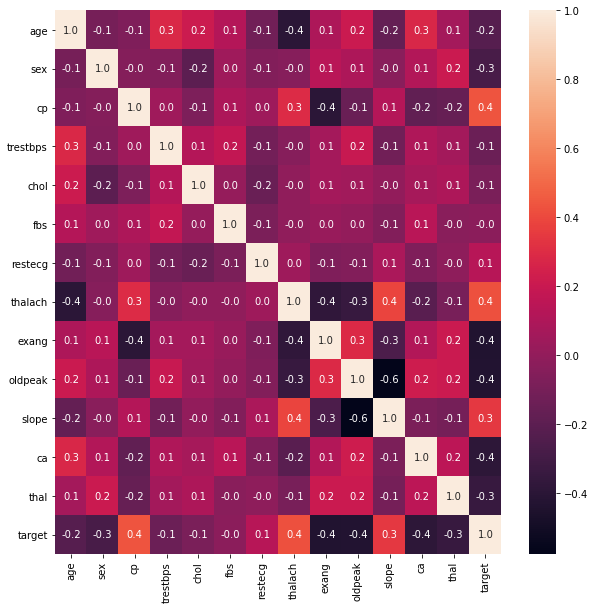

In [31]:
# Visualize the correlation between attributes
plt.figure(figsize =(10, 10))
sns.heatmap(df.corr(), annot=True, fmt='.1f')
plt.show()

main column target is more positively corrulated with slope. negative corulated with ca, oldpeak

In [32]:
#age analysis
#df.age.value_counts()
df.age.value_counts()[:10]


58    19
57    17
54    16
59    14
52    13
51    12
62    11
44    11
60    11
56    11
Name: age, dtype: int64

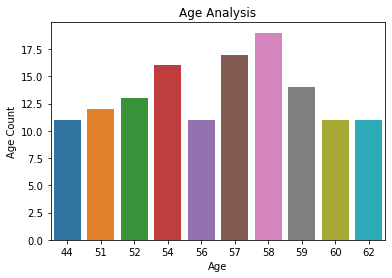

In [33]:
# visualize barplot
sns.barplot(x=df.age.value_counts()[:10].index, y=df.age.value_counts()[:10].values)
# give headings
plt.xlabel('Age')
plt.ylabel('Age Count')
plt.title('Age Analysis')

plt.show()

Lets check target column

In [34]:
df.target.value_counts()

1    165
0    138
Name: target, dtype: int64

###### We have 165 who have heart disease and 138 who has no heart disease

###### Percentage which has no heart disease

In [35]:
countNoDisease = len(df[df.target == 0])
countHaveDisease = len(df[df.target == 1])
percentNoDisease =(countNoDisease/(len(df.target)))*100
percentHaveDisease =(countHaveDisease/(len(df.target)))*100
print("Percentage of patients dont have heart disease: {:.2f}%".format(percentNoDisease))
print("Percentage of patients have heart disease: {:.2f}%".format(percentHaveDisease))

Percentage of patients dont have heart disease: 45.54%
Percentage of patients have heart disease: 54.46%


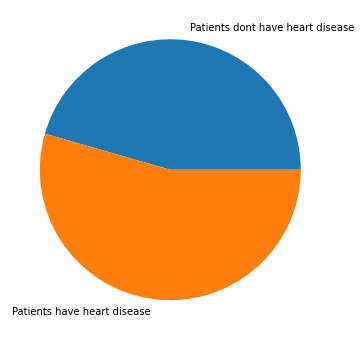

In [36]:
colors = ['red', 'green']
explode= [1,1,1]
plt.figure(figsize= (6,6))
plt.pie([percentNoDisease, percentHaveDisease], labels=['Patients dont have heart disease', 'Patients have heart disease'])
plt.show()

In [37]:
countFemale= len(df[df.sex == 0])
countMale = len(df[df.sex == 1])
print("Percentage of Female Patients: {:.2f}%".format((countFemale/(len(df.sex))*100)))
print("Percentage of male Patients: {:.2f}%".format((countMale/(len(df.sex))*100)))

Percentage of Female Patients: 31.68%
Percentage of male Patients: 68.32%


In [38]:
young_ages = df[(df.age>=29)&(df.age<40)]
middle_ages = df[(df.age>=40)&(df.age<55)]
elderly_ages = df[(df.age>=55)]
print("young ages", len(young_ages))
print("middle ages", len(middle_ages))
print("elderly ages", len(elderly_ages))

young ages 16
middle ages 128
elderly ages 159


#### Create a Pie chart

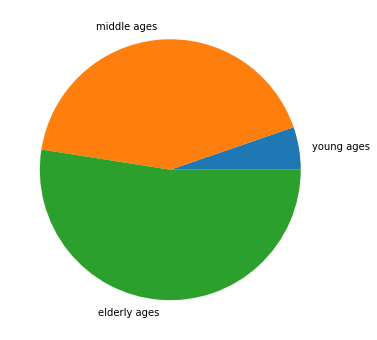

In [39]:
colors = ['blue','green', 'red']
explode= [1,1,1]
plt.figure(figsize= (6,6))
plt.pie([len(young_ages), len(middle_ages), len(elderly_ages)], labels=['young ages', 'middle ages', 'elderly ages'])
plt.show()

## Chest pain analysis

In [40]:
df.cp.value_counts()

0    143
2     87
1     50
3     23
Name: cp, dtype: int64

we have 4 types of chest pains of type 0 1 2 3

In [41]:
# make unique value
df.target.unique()

array([1, 0], dtype=int64)

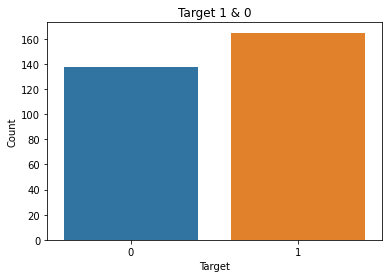

In [42]:
# Create a count plot
sns.countplot(df.target)
plt.xlabel('Target')
plt.ylabel('Count')
plt.title('Target 1 & 0')
plt.show()

Check the correlation again


In [43]:
df.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.098447,-0.068653,0.279351,0.213678,0.121308,-0.116211,-0.398522,0.096801,0.210013,-0.168814,0.276326,0.068001,-0.225439
sex,-0.098447,1.000000,-0.049353,-0.056769,-0.197912,0.045032,-0.058196,-0.044020,0.141664,0.096093,-0.030711,0.118261,0.210041,-0.280937
cp,-0.068653,-0.049353,1.000000,0.047608,-0.076904,0.094444,0.044421,0.295762,-0.394280,-0.149230,0.119717,-0.181053,-0.161736,0.433798
trestbps,0.279351,-0.056769,0.047608,1.000000,0.123174,0.177531,-0.114103,-0.046698,0.067616,0.193216,-0.121475,0.101389,0.062210,-0.144931
chol,0.213678,-0.197912,-0.076904,0.123174,1.000000,0.013294,-0.151040,-0.009940,0.067023,0.053952,-0.004038,0.070511,0.098803,-0.085239
fbs,0.121308,0.045032,0.094444,0.177531,0.013294,1.000000,-0.084189,-0.008567,0.025665,0.005747,-0.059894,0.137979,-0.032019,-0.028046
restecg,-0.116211,-0.058196,0.044421,-0.114103,-0.151040,-0.084189,1.000000,0.044123,-0.070733,-0.058770,0.093045,-0.072042,-0.011981,0.137230
thalach,-0.398522,-0.044020,0.295762,-0.046698,-0.009940,-0.008567,0.044123,1.000000,-0.378812,-0.344187,0.386784,-0.213177,-0.096439,0.421741
exang,0.096801,0.141664,-0.394280,0.067616,0.067023,0.025665,-0.070733,-0.378812,1.000000,0.288223,-0.257748,0.115739,0.206754,-0.436757
oldpeak,0.210013,0.096093,-0.149230,0.193216,0.053952,0.005747,-0.058770,-0.344187,0.288223,1.000000,-0.577537,0.222682,0.210244,-0.430696


we have positve correlation with chest pain and slope column. Negative correlation with exang  

## Build Model

Create Confusion Matrix

In [44]:
labels = ['Safe', 'Heart Attack']
def createConfusionMatrix(cm,labels):
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(cm)
    plt.title('Confusion Matrix for Gradient Boosting')
    fig.colorbar(cax)
    ax.set_xticklabels([''] + labels)
    ax.set_yticklabels([''] + labels)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()
    
def plotConfusionMatrix(test_true_labels,test_predictions_labels):
    ax= plt.subplot()

 

    cm = confusion_matrix(test_true_labels, test_predictions_labels)
    sns.heatmap(cm,annot = True, fmt='g', xticklabels=True,yticklabels = True )
    ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 

 


    ax.xaxis.set_ticklabels(labels)
    ax.yaxis.set_ticklabels(labels)

## Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression
x_data = df.drop(['target'], axis = 1)
y = df.target.values

In [46]:
#split train set and test set
x_train, x_test, y_train, y_test = train_test_split(x_data, y, test_size = 0.2, random_state=0)

In [47]:
# logistic regression fitting
lr = LogisticRegression()
lr.fit(x_train, y_train)
lr_predictions = lr.predict(x_test)
print('Test Accuracy {:.2f}%'.format(lr.score(x_test, y_test)*100))

Test Accuracy 85.25%


For different Senario we have different algorithms lets test KNN

Create Confusion Matrix

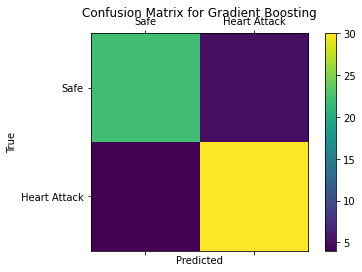

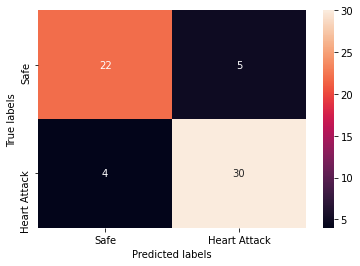

In [48]:
cm = confusion_matrix(y_test, lr_predictions)
#print(cm)
createConfusionMatrix(cm,labels)
plotConfusionMatrix(y_test, lr_predictions)

22 tanesinin kalp hastalığı yokmuş ve bizde doğru tahmin ettik.(çaprazlar doğru)
30 tanesinin kalp hastalığı varmış bve bizde kalp hastalığı var dedik
4 kalp sıkıntısı , yok çıkmış
5 kalp sıkıntısı yokmuş , biz vamrış

00 -> adam hasta değil ve bizde ne tahmin etmişiz temiz -> 22
01 -> adam kalp sorunu var, biz yok demişiz -> 5
10 -> biz sorun yok demişiz ama adam sorunlu -> 4 kişi
11 -> hem hasta var hem bizde hast a dedik -> 30 kşii

5+4 yanlis tahmin = 9 yanlisimiz var



## KNN Model

In [49]:
#KNN model
from sklearn.neighbors import KNeighborsClassifier
knn =  KNeighborsClassifier(n_neighbors = 39)  #3 varmis
#fit our model
knn.fit(x_train, y_train)
knn_predictions = knn.predict(x_test)
print("KNN accuracy: {:.2f}%".format(knn.score(x_test, y_test)*100))

KNN accuracy: 77.05%


Confusion Matrix

[[17 10]
 [ 4 30]]


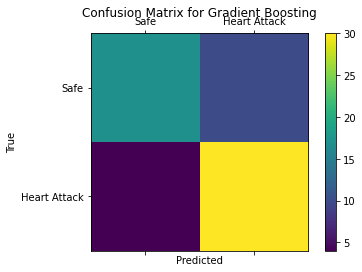

In [50]:
cm = confusion_matrix(y_test, knn_predictions)
print(cm)
createConfusionMatrix(cm,labels)

Burda mumkunse optimizaiyon yap

In [51]:
from sklearn.metrics import accuracy_score
best_knn = KNeighborsClassifier(n_neighbors=1)
best_knn.fit(x_train,y_train)
greatest_score = accuracy_score(best_knn.predict(x_test), y_test)
for i in range(2,100):
    current_knn = KNeighborsClassifier(n_neighbors=i)
    current_knn.fit(x_train, y_train)
    current_for_score = accuracy_score(current_knn.predict(x_test),y_test)
    
    if current_for_score > greatest_score:
        greatest_score = current_for_score
        best_knn = current_knn
 
print(best_knn)
    

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=39, p=2,
                     weights='uniform')


## Support Vector Machine

In [55]:
#SVM
from sklearn.svm import SVC
svm = SVC(random_state = 1)
svm.fit(x_train, y_train)
svm_predictions = svm.predict(x_test)
print("SVC accuracy: {:.2f}%".format(svm.score(x_test, y_test)*100))

SVC accuracy: 68.85%


Confusion Matrix


[[13 14]
 [ 5 29]]


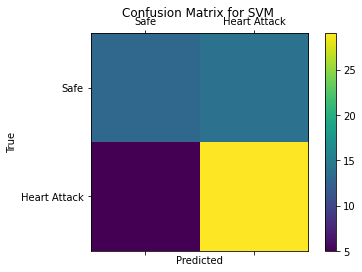

In [41]:
cm = confusion_matrix(y_test, svm_predictions)
print(cm)
createConfusionMatrix(cm,labels)

## Navie Bayes

In [74]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(x_train, y_train)
nb_predictions = nb.predict(x_test)
print("NB accuracy: {:.2f}%".format(nb.score(x_test, y_test)*100))

NB accuracy: 85.25%


Confusion Matrix

[[21  6]
 [ 3 31]]


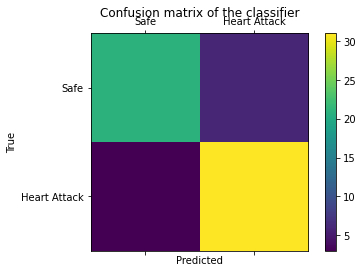

In [76]:
cm = confusion_matrix(y_test, nb_predictions)
print(cm)
createConfusionMatrix(cm,labels)

## Random Forest

In [59]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 1000, random_state= 1)
rf.fit(x_train, y_train)
print("Random Forest accuracy: {:.2f}%".format(rf.score(x_test, y_test)*100))

Random Forest accuracy: 85.25%


Summary
Similiar accurray for this problem in Navie bayes and Random forest. Suites best in this algorithms

In [48]:
n_estimators = [int(x) for x in np.linspace(start = 200, stop = 2000, num = 10)]
# Number of features to consider at every split
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)
# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]
# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]
# Method of selecting samples for training each tree
bootstrap = [True, False]
# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}
#print(random_grid)

In [49]:
rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 100, cv = 3, verbose=2, random_state=42, n_jobs = -1)

In [50]:
rf_random.fit(x_train, y_train)

Fitting 3 folds for each of 100 candidates, totalling 300 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  25 tasks      | elapsed:   18.9s
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed:  2.4min finished


RandomizedSearchCV(cv=3, error_score=nan,
                   estimator=RandomForestClassifier(bootstrap=True,
                                                    ccp_alpha=0.0,
                                                    class_weight=None,
                                                    criterion='gini',
                                                    max_depth=None,
                                                    max_features='auto',
                                                    max_leaf_nodes=None,
                                                    max_samples=None,
                                                    min_impurity_decrease=0.0,
                                                    min_impurity_split=None,
                                                    min_samples_leaf=1,
                                                    min_samples_split=2,
                                                    min_weight_fraction_leaf=0.0,
               

In [70]:
rf_predictions = rf.predict(x_test)

print(accuracy_score(y_test, rf_predictions)*100)
cm = confusion_matrix(y_test, rf_predictions)


85.24590163934425


Add explanation
22 dont pass attack it is accurate 4 has passed the attack
30 will pass attack and it is accurately predicted 5 false


[[17 10]
 [ 4 30]]


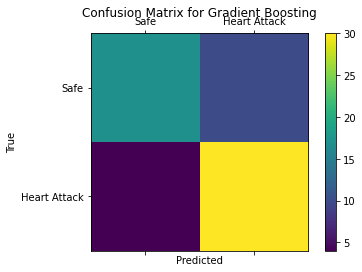

In [60]:
print(cm)
createConfusionMatrix(cm, labels)

Decision Tree

In [63]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier()
classifier.fit(X_train, y_train)
# Predicting the Test set results
y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_test = confusion_matrix(y_pred, y_test)

y_pred_train = classifier.predict(X_train)
cm_train = confusion_matrix(y_pred_train, y_train)

print()
print('Accuracy for training set for Decision Tree = {}'.format((cm_train[0][0] + cm_train[1][1])/len(y_train)))
print('Accuracy for test set for Decision Tree = {}'.format((cm_test[0][0] + cm_test[1][1])/len(y_test)))


Accuracy for training set for Decision Tree = 1.0
Accuracy for test set for Decision Tree = 0.7704918032786885


Gradient Boosting

In [53]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(n_estimators=7)
gb.fit(x_train, y_train)
gb_predictions = gb.predict(x_test)
print("Gradient Boosting accuracy: {:.2f}%".format(gb.score(x_test, y_test)*100))

Gradient Boosting accuracy: 83.61%


Notlar: Mümkünse optimize edelim, estimator değişşince accuracy değişiyor, Kaggle kazanananlardan , XGBOost,Lightgbm(çok hızlı ve iyi sonuç, turknet churn), Catboost(yandex, kategori encoding için çok iyi)

In [209]:
#lightgbm
import lightgbm as lgb
parameters = {
    'application': 'binary',
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': 'true',
    'boosting': 'gbdt',
    'num_leaves': 31,
    'feature_fraction': 0.5,
    'bagging_fraction': 0.5,
    'bagging_freq': 20,
    'learning_rate': 0.01,
    'verbose': 0,
    'num_iterations':49
}

train_data  = lgb.Dataset(x_train,label=y_train)
test_data = lgb.Dataset(x_test, label=y_test)

lgb_model = lgb.train(train_set=train_data, params = parameters)

In [210]:
lgb_predictions = lgb_model.predict(x_test)
predictions_lgbm = np.where(lgb_predictions > 0.5, 1, 0) #Turn probability to 0-1 binary output

print(accuracy_score(y_test, predictions_lgbm))

0.8524590163934426


overfitting problem cogu itration 50 gecince dusuyor

Confusion matrix

In [213]:
cm = confusion_matrix(y_test, rf_predictions)
print(cm)

[[22  5]
 [ 4 30]]


[[22  5]
 [ 4 30]]


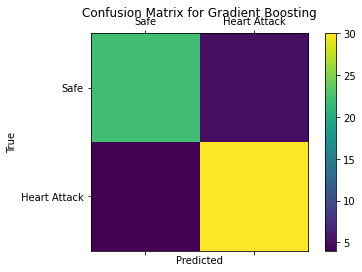

In [56]:
print(cm)
createConfusionMatrix(cm, labels)

In [69]:
################################################################################ applying XGBoost

#from sklearn.model_selection import train_test_split
#X_train, X_test, y_train, y_test = train_test_split(X, target, test_size = 0.20, random_state = 0)

from xgboost import XGBClassifier
xg = XGBClassifier()
xg.fit(X_train, y_train)
y_pred = xg.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_test = confusion_matrix(y_pred, y_test)

y_pred_train = xg.predict(X_train)

for i in range(0, len(y_pred_train)):
    if y_pred_train[i]>= 0.5:       # setting threshold to .5
       y_pred_train[i]=1
    else:  
       y_pred_train[i]=0
       
cm_train = confusion_matrix(y_pred_train, y_train)
print()
#print('Accuracy for training set for XGBoost = {}'.format((cm_train[0][0] + cm_train[1][1])/len(y_train)))
print('Accuracy for test set for XGBoost = {:.2f}%'.format((cm_test[0][0] + cm_test[1][1])/len(y_test)*100))



Accuracy for test set for XGBoost = 78.69%
